In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns




In [5]:
data = pd.read_csv("sample_data/CA12_Dataset (1).csv")
data.head()

,Order_ID,Order_Date,Region,Product_Category,Units_Sold,Unit_Price_EUR,Discount_Rate,Revenue_EUR
0,R0001,08/01/2025,North,Electronics,8,112,0.15,761.6
1,R0002,22/01/2025,North,Electronics,15,105,0.00,1575.0
2,R0003,08/01/2025,North,Home,18,70,0.15,1071.0
3,R0004,22/01/2025,North,Home,17,72,0.15,1040.4
4,R0005,08/01/2025,North,Clothing,18,41,0.00,738.0


- Explore the dataset and check whether any data preparation is needed.

In [7]:
#check size of the data set

data.shape

(384, 8)

In [10]:
#checking data types
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 384 entries, 0 to 383
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          384 non-null    object 
 1   Order_Date        384 non-null    object 
 2   Region            384 non-null    object 
 3   Product_Category  384 non-null    object 
 4   Units_Sold        384 non-null    int64  
 5   Unit_Price_EUR    384 non-null    int64  
 6   Discount_Rate     384 non-null    float64
 7   Revenue_EUR       384 non-null    float64
dtypes: float64(2), int64(2), object(4)
memory usage: 24.1+ KB


Order_Date is object but it should be datetime.

In [18]:
#conversion of Order_date

data["Order_Date"] = pd.to_datetime(
    data["Order_Date"],
    format="%d/%m/%Y"
)

data.dtypes

,0
Order_ID,object
Order_Date,datetime64[ns]
Region,object
Product_Category,object
Units_Sold,int64
Unit_Price_EUR,int64
Discount_Rate,float64
Revenue_EUR,float64


In [25]:
#basic descriptive statistic
data.describe()

,Order_Date,Units_Sold,Unit_Price_EUR,Discount_Rate,Revenue_EUR
count,384,384.000000,384.000000,384.000000,384.000000
mean,2025-06-30 12:00:00,20.479167,69.177083,0.066146,1282.798437
min,2025-01-08 00:00:00,8.000000,34.000000,0.000000,440.300000
25%,2025-04-03 18:00:00,18.000000,50.000000,0.000000,954.987500
50%,2025-06-30 00:00:00,21.000000,62.000000,0.050000,1219.000000
75%,2025-09-26 00:00:00,24.000000,80.250000,0.112500,1498.200000
max,2025-12-22 00:00:00,32.000000,118.000000,0.150000,2950.000000
std,NaN,4.447499,25.331018,0.060132,459.112090


In [12]:
#checking for missing values
data.isnull().sum()

,0
Order_ID,0
Order_Date,0
Region,0
Product_Category,0
Units_Sold,0
Unit_Price_EUR,0
Discount_Rate,0
Revenue_EUR,0


In [13]:
#checking for duplicate values
data.duplicated().sum()

np.int64(0)

In [14]:
#checking if Order ID is unique
data["Order_ID"].duplicated().sum()

np.int64(0)

In [20]:
#checking Measures of central tendency
print(data["Revenue_EUR"].mean())
print(data["Revenue_EUR"].median())
print(data["Revenue_EUR"].std())

1282.7984374999999
1219.0
459.1120903853677


In [21]:
#checking the count of all cathegories in Region
data["Region"].value_counts()

,count
Region,
North,96
South,96
East,96
West,96


In [22]:
#checking the count of all cathegories in Product Cateogry
data["Product_Category"].value_counts()

,count
Product_Category,
Electronics,96
Home,96
Clothing,96
Sports,96


In [24]:
#listing the cathegories in Product Cateogry and Region
print(data["Region"].unique())
print(data["Product_Category"].unique())

['North' 'South' 'East' 'West']
['Electronics' 'Home' 'Clothing' 'Sports']


•	Create five appropriate, clearly labelled Python charts, including a time-series chart and comparisons across business categories.

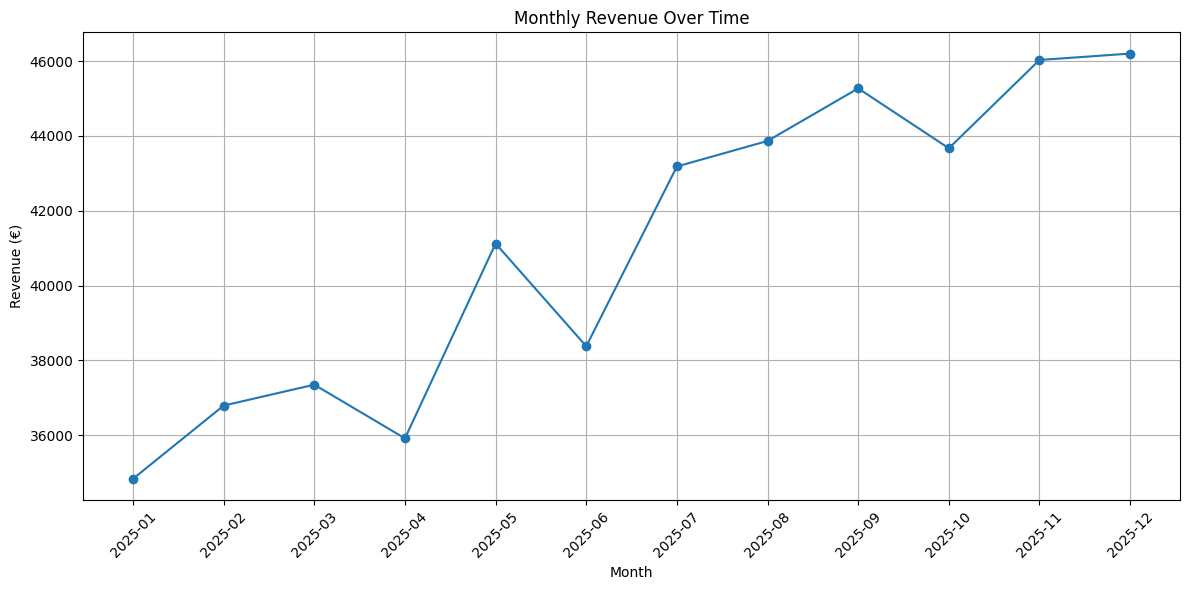

In [27]:
#Time-series line chart: Revenue over time -> To analyze how revenue changes over time

# Calculate monthly revenue
monthly_revenue = data.groupby(
    data["Order_Date"].dt.to_period("M")
)["Revenue_EUR"].sum()

# Create line chart
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue Over Time")
plt.xlabel("Month")
plt.ylabel("Revenue (€)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


Interpretation: The time-series chart shows an overall increasing trend in monthly revenue throughout 2025. Revenue increased from around €34 thousand in January to around €46 thousand in December, representing an increase of approximately 33%. Although some monthly fluctuations occurred, the general trend indicates positive business performance and growing revenue over the year. The highest revenue was recorded in December, while January had the lowest revenue.

Insight: Revenue generally increases towards the end of the year. This could indicate stronger customer demand during the later months.

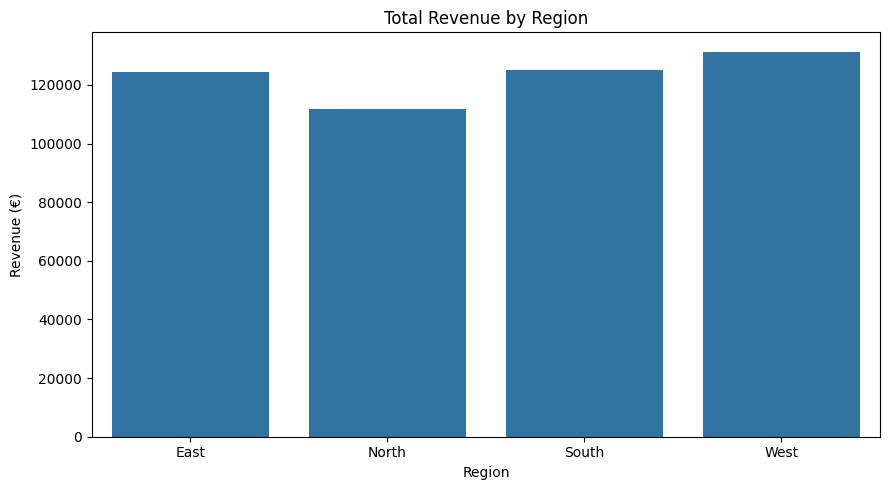

In [28]:
# Bar chart: Revenue by Region -> To compare business performance across four regions

# Calculate revenue by region
region_revenue = data.groupby("Region")["Revenue_EUR"].sum()

# Create bar chart
plt.figure(figsize=(9, 5))

sns.barplot(
    x=region_revenue.index,
    y=region_revenue.values
)

plt.title("Total Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue (€)")
plt.tight_layout()
plt.show()

Interpretation: The bar chart indicates that the West region generated the highest total revenue, followed by the South and East regions. The North region recorded the lowest revenue. As all regions have an equal number of orders, the revenue differences suggest variations in average order value across regions. This indicates that regional sales performance differs despite an equal number of transactions.

Insight: The West performs best, while the North represents an opportunity for improvement.

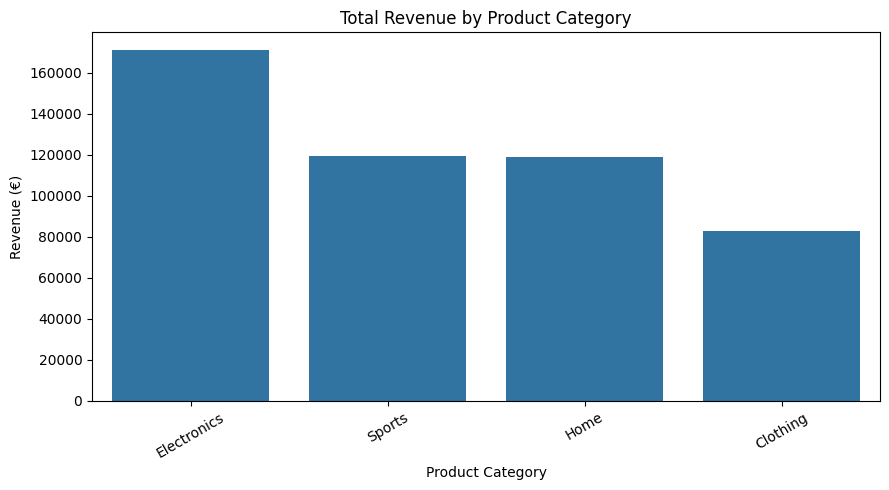

In [29]:
#Bar chart: Revenue by Product Category - To compare revenue generated by different product categories

# Calculate revenue by product category
category_revenue = data.groupby(
    "Product_Category"
)["Revenue_EUR"].sum().sort_values(ascending=False)

# Create bar chart
plt.figure(figsize=(9, 5))

sns.barplot(
    x=category_revenue.index,
    y=category_revenue.values
)

plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue (€)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Interpretation: The chart shows that Electronics is the highest-performing product category, generating. Sports and Home generate relatively similar revenue, while Clothing records the lowest revenue. As each product category contains 96 orders, these differences reflect variations in revenue generated per order rather than differences in order volume. Electronics therefore represents the strongest revenue-generating category.

Insight: Electronics is the main revenue driver. Clothing has the greatest potential for further sales improvement.

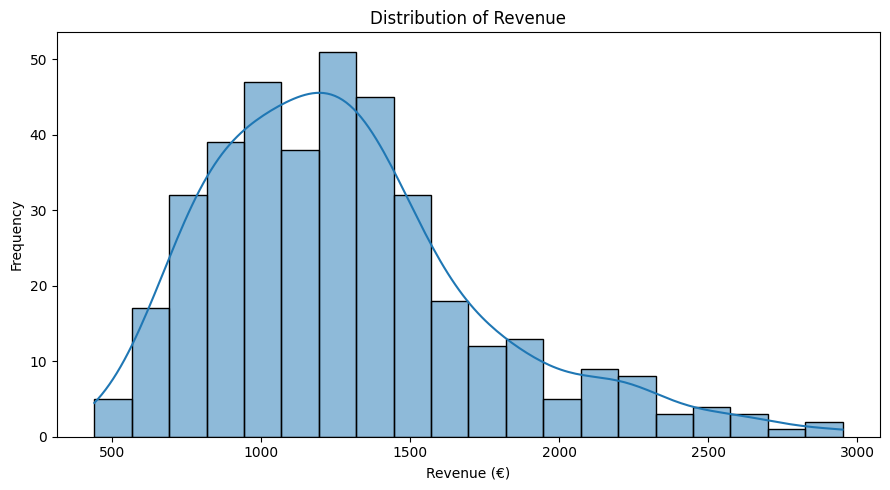

In [30]:
#Histogram: Distribution of Revenue -> To examine the distribution of revenue values

plt.figure(figsize=(9, 5))

sns.histplot(
    data=data,
    x="Revenue_EUR",
    bins=20,
    kde=True
)

plt.title("Distribution of Revenue")
plt.xlabel("Revenue (€)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

Interpretation: The histogram shows the distribution of revenue across individual orders. The mean revenue is higher than the median, suggesting a positively skewed distribution. Most orders are concentrated around the central revenue range, while a smaller number of orders generate considerably higher revenue. This indicates that some high-value transactions increase the overall average revenue.

Insight: The business should investigate what drives high-value orders and identify opportunities to increase the average order value.

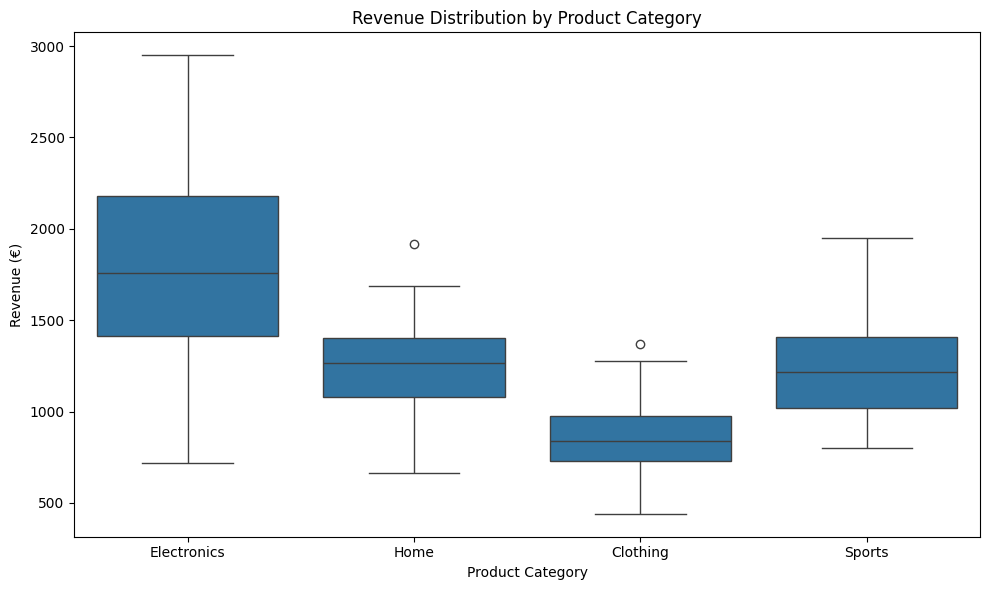

In [31]:
#Boxplot: Revenue by Product Category -> To compare revenue distribution across product categories and identify potential outliers

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=data,
    x="Product_Category",
    y="Revenue_EUR"
)

plt.title("Revenue Distribution by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue (€)")
plt.tight_layout()
plt.show()

Interpretation: The boxplot highlights differences in revenue distribution across product categories. Electronics has the highest median revenue per order, considerably exceeding the other categories. Clothing has the lowest median. Home and Sports show relatively similar median values. The chart also identifies potential outliers in Clothing and Home, indicating a small number of unusually high-value orders. Overall, Electronics consistently generates higher revenue per transaction.

Insight: Electronics generates substantially higher revenue per transaction, while Clothing has the lowest typical order value.

### Business Recommendations

**Recommendation 1: Focus on improving Clothing category performance**

The analysis identifies Clothing as the lowest-performing product category. Its median revenue per order is also significantly lower than other categories. The business should consider targeted promotional campaigns, product bundling and cross-selling strategies to increase customer spending in this category. The objective should be to improve average order value and increase Clothing's contribution to total revenue.

**Recommendation 2: Improve regional performance and optimise seasonal planning**

The West region generated the highest revenue, while the North recorded the lowest, despite both having an equal number of orders. The business should investigate differences in regional purchasing behaviour and identify successful sales practices in the West that could be applied to the North. Additionally, the time-series analysis shows around 33% increase in monthly revenue between January and December. The business should consider adjusting inventory and staffing levels to accommodate potentially higher demand towards the end of the year.

However, the dataset covers only one year (2025). Therefore, the increase towards December does not establish a recurring seasonal pattern. Similarly, revenue does not equal profit, so the recommendations should be evaluated against product margins and operating costs before implementation.